# Т-Интенсив. Управление рисками
## Август 2026

## Часть 1. График линейности признака по WoE.

В этой части домашки мы познакомимся с одним из основных инструментов для анализа переменных в модели логистической регрессии - графиком линейности. 

Кратко идею этого графика можно сформулировать так:
 - модель *линейной* регрессии корректно применять, если значение $y$ *линейно* связано со значением $x$. Иначе линрег не подходит для данной задачи и даст неверные результаты.
 - аналогичную проверку хочется сделать и для *логистической* регрессии. Но как проверить линейность, если таргет принимает всего два значения?
 - для этого необходимо преобразовать таргет: разбить признак на бакеты и в каждом бакете посчитать WoE
 - **линейность признака по WoE для логрега – аналог линейной связи признака и таргета для линрега**

Ниже пример признака с неплохой линейностью:

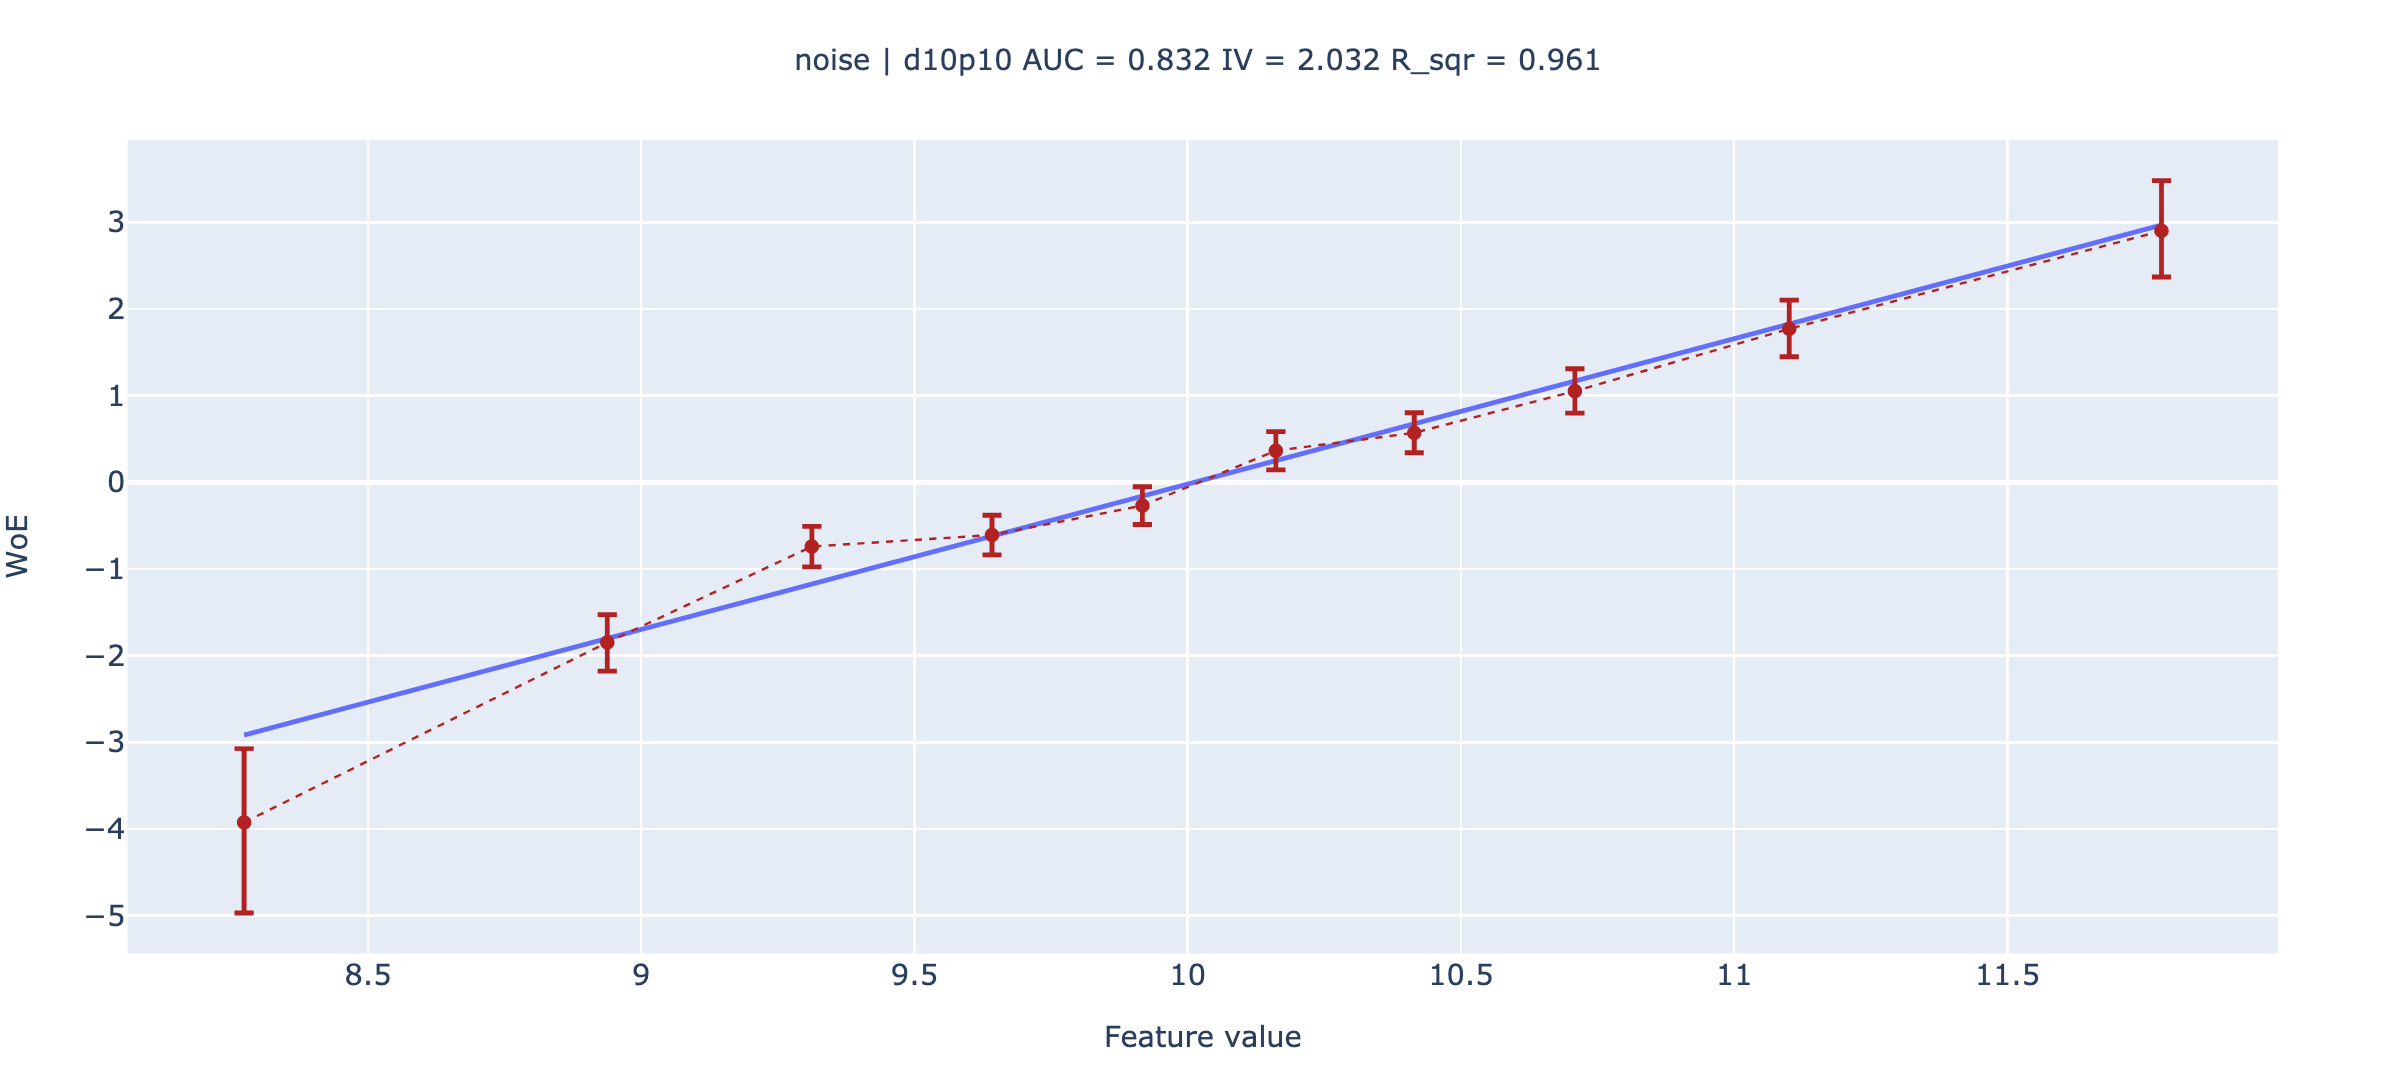

Нам нужно обратить внимание на 3 вещи:

**1. Фиолетовые точки с доверительными интервалами.**

Это WoE для каждого отдельного бакета. В идеале нам бы хотелось, чтобы **через эти точки можно было провести прямую линию** с небольшой погрешностью. Это и означает линейную взаимосвязь с таргетом.

**2. Синяя линия**

Попытка провести прямую линию через точки. Строится с помощью логистической регрессии на одной переменной. Затем предсказания переводятся в пространство WoE, отчего и получается прямая линия.

**3. Метрики в заголовке графика**

Метрики для признака:
 - roc auc, IV измеряют разделяющую способность переменной
 - $R^2$ измеряет *линейность взаимосвязи*. Признак считается линейным, если $R^2 \geq 0.95$

Далее напишем woe-line руками, чтобы в деталях разобраться, как он строится.

In [658]:
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as sps
from typing import Union, Tuple

### Шаг 0: разбиение на бакеты

In [659]:
def calc_buckets(x : Union[np.ndarray, pd.Series], n_buckets : int) -> np.ndarray:
    """Разбивает массив значений признака x на 
    n_buckets бакетов"""

    x = pd.Series(x).reset_index(drop=True)
    buckets = x.rank(method="dense", pct=True) * n_buckets
    buckets = np.ceil(buckets) - 1   # np.floor дает другой результат для 5.0, 6.0 и т.д.
    buckets = np.array(buckets, dtype=np.int16)

    return buckets

In [660]:
# протестируйте calc_buckets
x_test = np.random.random(size = 10_000) * 10_000
print(x_test)

buckets = calc_buckets(x_test, n_buckets=100)
buckets.shape, buckets

[3472.48998192 8226.78164478 7648.99529699 ...   74.413439   5842.11595902
  904.93795357]


((10000,), array([34, 82, 76, ...,  0, 58,  9], dtype=int16))

### Шаг 1: расчет WoE по бакетам (3 балла)

Пусть $x_i \in \{ 0, 1\}^n$

$x_i$ - это вектор, состоящий из значений таргета *в одном бакете* $i$. 

Для бакета можно посчитать количество единиц $B_i$ (bads, выпавшие в дефолт) и количество нулей $G_i$ (goods).

$$
B_i = \sum_{j \in x_i} \mathbb{I} \{ j = 1\}\quad G_i = \sum_{j \in x_i} \mathbb{I} \{ j = 0\}
$$

Также число бэдов и гудов можно посчитать и **для всей выборки**: 

$$
% X = x_1 \cup x_2 \ldots \cup x_n
X = \{x_1,\; x_2\; \ldots\; x_n\}
$$

$$
B = \sum_{j \in X} \mathbb{I} \{ j = 1\}\quad G = \sum_{j \in X} \mathbb{I} \{ j = 0\}
$$

Тогда WoE можно посчитать как

$$
\text{WoE}_i(x) = \ln \Big ( \frac{B_i}{G_i} \Big ) - \ln \Big ( \frac{B}{G} \Big ) 
$$

**Задание**

Убедиться, что

$$
\text{WoE}_i(x) = \text{logit}(b_i) - \text{logit}(b)\quad  (1)
$$

где 

$$
b = \frac{B}{B + G}\quad \text{logit}(p) = \ln \Big (  \frac{p}{1 - p} \Big )
$$

В дальнейшем будем считать WoE по формуле $(1)$

In [661]:
from scipy.special import logit

def woe_transform(badrate : float, offset : float) -> float:
    """Считаем WoE для бакета с данным badrate и выборки
    с данным offset."""
    woe = logit(badrate) - offset
    return woe

Здесь и далее предлагается протестироать получившиеся функции. Нужно проверить, что
 - функция не ложится с ошибкой
 - возвращает то, что ожидается

<div align="center">
  Важное замечание!

  Я решил написать это здесь, потому что, кажется, ровно здесь и начинается первая уже авторская писанина, которую будут проверять $\Rightarrow$ будут отсматривать. Мне немного было больно от формализации терминов, потому что местами встречаются опечатки, а местами сделан резкий переход от многомерного случая к одномерному, из-за которого при просмотре конспекта я долго медитировал.
</div>

Пусть у нас есть две случайных величины $\xi = (\xi_1, ..., \xi_n), y$, причём они зависимые, то есть у них существует какое-то совместное распределение $P_{\xi \cdot y}$. Мы хотим сделать так, чтобы $w^T\xi \approx \ln(\frac{P(y = 1 | \xi)}{P(y = 0 | \xi)})$, но если мы предполагаем, что фичи независимы в совокупности, то случайная величина справа в силу теоремы Байеса превращается в:
$$
\ln(\frac{P(y = 1 | \xi)}{P(y = 0 | \xi)}) = \sum_{i=1}^n [\ln(\frac{P(y = 1 | \xi_i)}{P(y = 0 | \xi_i)}) - \ln(\frac{P(y = 1)}{P(y = 0)})] + \ln(\frac{P(y = 1)}{P(y = 0)}) =: \sum_{i = 1}^n \text{WoE}(\xi_i) + \ln(\frac{P(y = 1)}{P(y = 0)})
$$
Поэтому будем считать, что $\text{WoE}(\xi_i) =: \text{WoE}_i$ - это случайная величина, зависимая от $\xi_i$, соответственно, если мы пишем $\text{WoE}_i(x)$, то мы имеем в виду, что $\text{WoE}_i(x) = \ln(\frac{P(\xi_i = x | y = 1)}{P(\xi_i = x | y = 0)}) = \ln(\frac{P(y = 1 | \xi_i = x)}{P(y = 0 | \xi_i = x)}) - \ln(\frac{P(y = 1)}{P(y = 0)})$. Поэтому нам важна линейность $\text{WoE}_i$ от $\xi_i \ \forall i$, потому что тогда лог-шанс действительно превращается во что-то линейное от $\xi$, и всё становится классно.

<div align="center">
    Конец важного замечания!

    P.S Я действительно потратил 20 минут, чтобы сказать, что $\text{WoE}_i(x)$ - это конкретная реализация случайной величины от конкретной фичи, спасибо за внимание! 
</div>

Протестируем стандартно: сгенерируем выборку из смешного распределения, разобьём её по бакетам функцией с прошлого шага, поинтересуемся состоянием 42-ого бакета. Кроме того, сделаем какой-то необычный бинарный таргет, прогоним изначальную формулу, посчитав WoE вручную, затем прогоним через новую функцию.

In [665]:
# протестируй woe_transform
sample = np.random.random(size = 10_000) * 10_000 + np.random.normal(loc=5000, scale=70)
target =  np.round(sample % 1337) >= 500
print(sample, target.mean())

buckets = calc_buckets(sample, n_buckets = 100)
bucket_s = sample[buckets == 42]
bucket_t = target[buckets == 42]

bads = bucket_t.sum()
goods = len(bucket_t) - bads

old_form = np.log(bads / goods) - np.log(target.sum() / (len(target) - target.sum()))
print(f"Значение, посчитанное через изначальную формулу:\n{old_form}")

new_form = woe_transform(bads / len(bucket_t), offset=logit(target.sum() / len(target)))
print(f"Значение, посчитанное через логиты:\n{new_form}")

print(f"Примерно равны ли:\n{np.isclose(new_form, old_form)}")

[13355.40792748  6355.58908073 14637.02281339 ...  5615.33051338
  8000.11213163  6684.6116445 ] 0.6164
Значение, посчитанное через изначальную формулу:
1.839339168743953
Значение, посчитанное через логиты:
1.8393391687439538
Примерно равны ли:
True


### Доверительные интервалы (3 балла)

Ниже представлен шаблон функции, которая будет считать доверительный интервал к нашим вычислениям. Можно воспользоваться любым способом, который вам больше нравится. Для идей можно посмотреть различные способы подсчета доверительного интервала [здесь](https://en.wikipedia.org/wiki/Binomial_proportion_confidence_interval).

**P. S.**
Для того, чтобы построить доверительный интервал к $WoE$, можно сначала построить его для величины  $b_i = \frac{B_i}{B_i+G_i}$, а потом применить ```woe_transform```. В свою очередь величина $b_i$ является параметром распределения Бернулли, который мы можем оценить классическими методами (см. ссылку выше)

Будем использовать вполне стандартный метод построения: Метод Вальда. Пусть мы интересумся каким-то конкретным бакетом таргета $y_i$ (например, $\xi_j$ принимает в этом бакете значения $x_i$, поэтому нас это интересует). Этот бакет мы можем представить в виде выборки $(X_1, \dots, X_m), \ X_i \sim^{\text{iid}} Bern(b_i)$. Тогда на этот параметр мы можем построить следующий доверительный интервал, пусть $S_m := \sum_{i=1}^m X_i$:
$$
P_{b_i} ([\frac{S_m}{m} - \frac{z_{1 - \frac{\alpha}{2}} \sqrt{S_m(m-S_m)}}{m\sqrt{m}}, \frac{S_m}{m} + \frac{z_{1 - \frac{\alpha}{2}} \sqrt{S_m(m-S_m)}}{m\sqrt{m}}]) = 1 - \alpha
$$
Но мы делаем оценку на $\text{WoE}_j(x_i) = logit(b_i) - logit(b)$, где $b$ - это оценка на распределение Бернулли всей выборки, поэтому наш итоговый интервал будет иметь вид:
$$
P_{\text{WoE}_j(x_i)}([logit(\frac{S_m}{m} - \frac{z_{1 - \frac{\alpha}{2}} \sqrt{S_m(m-S_m)}}{m\sqrt{m}}) - logit(b), logit( \frac{S_m}{m} + \frac{z_{1 - \frac{\alpha}{2}}\sqrt{S_m(m-S_m)}}{m\sqrt{m}}) - logit(b)]) = 1 - \alpha
$$

In [666]:
def woe_ci(target : np.ndarray, buckets : np.ndarray, offset : float) -> Tuple[pd.Series]:
    """Для каждого бакета вычисляем WoE и доверительный
    интервал для него."""
    # считаем бэдрейт и доверительный интервал для него (любым способом)
    badrate, badrate_lower, badrate_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
        badrate[bucket] = target[buckets == bucket].mean()
        add_val = sps.norm.ppf(1 - 0.05 / 2, loc = 0, scale = 1) * ((badrate[bucket]) * (1 - badrate[bucket]) / len(target[buckets == bucket]))**0.5
        badrate_lower[bucket] =  badrate[bucket] - add_val
        badrate_upper[bucket] =  badrate[bucket] + add_val

    # переходим от бэдрейта к woe
    woe, woe_lower, woe_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
            woe[bucket] = woe_transform(badrate=badrate[bucket], offset=offset)
            woe_lower[bucket] = woe_transform(badrate = badrate_lower[bucket], offset = offset)
            woe_upper[bucket] = woe_transform(badrate = badrate_upper[bucket], offset=offset)
    return woe, woe_lower, woe_upper

### Шаг 2: расчет линейной интерполяции (1 балл)

In [667]:
from sklearn.linear_model import LogisticRegression

def calc_line(values : np.ndarray, target : np.ndarray, mean_feature : np.ndarray, offset : float) -> np.ndarray:
    """Строим линейную интерполяцию для WoE."""

    # строим логистическую регрессию на одном признаке
    # и считаем ее предсказания в точках – mean_feature

    model = LogisticRegression()
    model = model.fit(values.reshape(-1, 1), target) # reshape, иначе ругается sklearn

    # .predict_proba возвращает матрицу (n_samples, n_classes)
    # простыми словами он возращает матрицу вида:
    # (P(y = 0 | x_1), P(y = 1 | x_1))
    # (...)
    # (P(y = 0 | x_n), P(y = 1 | x_n))
    # Так как в логреге мы интересуемся P(y = 1 | X), 
    # то и берём мы только второй столбец.

    proba = model.predict_proba(mean_feature.reshape(-1, 1))[:, 1]
    line = woe_transform(proba, offset)
    return line

In [668]:
# протестируйте calc_line
sample = np.random.random(size = 10_000) * 10_000 + np.random.normal(loc=5000, scale=70)
target =  np.round(sample % 1337) >= 500

buckets = calc_buckets(sample, n_buckets = 100)
mean_feature = []

for i in range(100):
    mean_feature.append(sample[buckets == i].mean())

res = calc_line(sample, target, np.array(mean_feature), logit(target.mean()))
res, res.shape

(array([-0.04158849, -0.04067321, -0.03984694, -0.03900399, -0.038221  ,
        -0.03736871, -0.03656597, -0.03573377, -0.03484974, -0.0339675 ,
        -0.03314426, -0.03226741, -0.03143172, -0.03059549, -0.02966825,
        -0.02881712, -0.02791694, -0.02702099, -0.02621895, -0.02542992,
        -0.02447065, -0.02359671, -0.02280278, -0.02209822, -0.02125228,
        -0.02045192, -0.01955681, -0.01872488, -0.01789177, -0.01705608,
        -0.0162965 , -0.01558194, -0.01468783, -0.01390846, -0.01313915,
        -0.01233399, -0.0114694 , -0.01064654, -0.00980119, -0.00894412,
        -0.00809303, -0.00724587, -0.00639096, -0.00554267, -0.00475169,
        -0.0039458 , -0.00305364, -0.00213798, -0.00125265, -0.0004519 ,
         0.00032063,  0.00113897,  0.00202928,  0.00289877,  0.00376071,
         0.00465937,  0.00563379,  0.00649793,  0.00740864,  0.0082196 ,
         0.00894502,  0.00977268,  0.01066434,  0.01149956,  0.01229032,
         0.01321839,  0.01418919,  0.01501706,  0.0

### Шаг3: собираем результаты по бакетам в один словарь

In [669]:
def calc_buckets_info(values : np.ndarray, target : np.ndarray, buckets : np.ndarray) -> dict:
    """Для каждого бакета расчитывает
     - среднее значение признака
     - линейную интерполяцию в пространстве woe
     - значение woe и доверительный интервал для него"""

    mean_feature = np.array([values[buckets == i].mean() for i in sorted(set(buckets))])
    offset = logit(target.mean())
    woe, woe_lower, woe_upper = woe_ci(target, buckets, offset)
    buckets_info = {
        "mean_feature" : mean_feature,
        "line"         : calc_line(values, target, mean_feature, offset),
        "woe"          : woe,
        "woe_lower"    : woe_lower,
        "woe_upper"    : woe_upper
    }

    return buckets_info

In [670]:
# протестируйте calc_buckets_info
sample = np.random.random(size = 10_000) * 10_000 + np.random.normal(loc=5000, scale=70)
target =  np.round(sample % 1337) >= 500
buckets = calc_buckets(sample, n_buckets = 20)

calc_buckets_info(sample, target, buckets)["woe"]

0     0.291642
1    -1.108005
2          inf
3    -1.425740
4     0.725716
5     1.412053
6    -2.624886
7          inf
8    -0.343161
9    -0.583454
10         inf
11   -2.205937
12    1.311121
13    1.100182
14   -2.886814
15         inf
16    0.086708
17   -1.318634
18         inf
19   -0.827040
dtype: float64

Тут не стоит пугаться бесконечностей, потому что бывает, что в бакетах вообще нет бэдов или нет гудов, из-за чего всё взрывается.

### Шаг 4: считаем метрики признака (3 балла)

Рассчитаем также несколько метрик, чтобы судить о качестве признака не только по картинкам. 

Приведем формулу для IV:

$$
\text{IV}(x) = \sum_{i = 1}^{n}\Big ( \frac{B_i}{B} - \frac{G_i}{G} \Big ) \times \text{WoE}_i
$$

**Вопрос:** зачем считать ранжирующую силу признака двумя способами? Какую дополнительную информацию может дать IV относительно roc auc?

Продолжаем наши формализационные приключения, теперь мы пришли к IV - по сути детерменированному функционалу от фичи, пусть у нас $\xi_i$ - абсолютно непрерывная (или дискретная) случайная величина, тогда:
$$
IV_i := IV(\xi_i) = D_{KL}(p_{\xi | y = 1} || p_{\xi | y = 0}) + D_{KL}(p_{\xi | y = 0} || p_{\xi | y = 1}) = \int_{\mathbb{R}} [P(\xi_i = x | y = 1) - P(\xi = x | y = 0)] \cdot \text{WoE}_i(x) dx
$$
Для дискретной, очевидно, интеграл превратится в сумму. Тогда отсюда как раз та формула оценки на IV для i-oй дискретной фичи ($\xi_i \in \{x_1, \dots, x_m\}$):
$$
\overline {IV_i} = \sum_{j=1}^m [\frac{B_j}{B} - \frac{G_j}{G}] \cdot \text{WoE}_i(x_j)
$$

**Ответ**:
Будем считать, что мы рассуждаем в контексте одной фичи. Если выполнены сильные предпосылки (например, нормальные распределения с одинаковыми дисперсиями), то одна метрика выражается через другую, однако в общем случае эти две метрики используются для немного разных целей: ROC-AUC считает, насколько фича хорошо ранжирует в целом, она даёт информацию о глобальном порядке, поэтому сравнивать силу признаков через эту метрику можно только в смысле общей ранжирующей способности; IV же в свою очередь позволяет сравнивать признаки между собой и выбирать наиболее информативные, например, чем больше эта метрика, тем сильнее отличаются условные распределения (потому что дивергенции как раз расстояния между распределениями и считает), а значит, вполне может быть такое, что некоторые значения для $y = 1$ будут появляться у фичи настолько редко, но при этом настолько часто при $y = 0$, что по каким-то конкретным значениям можно будет сразу сказать о наиболее вероятном классе, подобной информации о разнице распределений не может показать roc-auc. Кроме того, IV показывает вклад по бакетам, поэтому мы получаем ещё больше локальной информации о фиче. Поэтому ранжирующую силу можно считать двумя способами: одним для общей картины, другим для конкретных особенностей.

In [671]:
from sklearn.metrics import roc_auc_score

def calc_plot_title(
        values : np.ndarray,
        target : np.ndarray,
        buckets : np.ndarray
    ) -> str:
    """Считает для признака roc auc, IV, R^2"""
    auc = roc_auc_score(target, values)

    # формула выше
    total = len(target)
    bads = target.sum()
    goods = total - bads
    offset = logit(target.mean())
    IV = sum(
            [
            ((bads_i := target[buckets == i].sum()) / bads - ((m := len(target[buckets == i])) - bads_i) / goods) * 
            woe_transform(bads_i / m, offset)   for i in sorted(set(buckets))
            ]
        ) # простите за это..

    # Взвешенный R^2 
    # X - среднее в бакете, Y - woe в бакете, вес – число наблюдений в бакете

    # Будем считать как квадрат корреляции, потому что здесь -
    # https://en.wikipedia.org/wiki/Coefficient_of_determination
    # - так написано, а кто я такой, чтобы не верить?

    X_arr = []
    w_arr = []
    woe_buck, _, _ = woe_ci(target, buckets, offset)
    woe_buck = np.asarray(woe_buck)
    
    for i in sorted(set(buckets)):
        bucket = target[buckets == i]
        X_arr.append(values[buckets == i].mean())
        w_arr.append(len(bucket))

    w_arr = np.array(w_arr)
    X_arr = np.array(X_arr)

    w_s = w_arr.sum()
    X_w_mean = np.sum([w_arr[i] * X_arr[i] for i in range(len(set(buckets)))]) / w_s
    Y_w_mean = np.sum([w_arr[i] * woe_buck[i] for i in range(len(set(buckets)))]) / w_s

    X_arr = X_arr - X_w_mean
    woe_buck = woe_buck - Y_w_mean

    cov = np.sum([w_arr[i] * X_arr[i] * woe_buck[i] for i in range(len(set(buckets)))]) / w_s
    var_x = np.sum([w_arr[i] * X_arr[i] ** 2 for i in range(len(set(buckets)))]) / w_s
    var_y = np.sum([w_arr[i] * woe_buck[i] ** 2 for i in range(len(set(buckets)))]) / w_s

    R_sqr = cov ** 2 / (var_x * var_y)

    plot_title = (        
        f"AUC = {auc:.3f} "
        f"IV = {IV:.3f} "
        f"R_sqr = {R_sqr:.3f} "
    )

    return plot_title

In [673]:
# протестируйте calc_plot_title
sample = np.random.random(size = 10_000) * 10_000 + np.random.normal(loc=5000, scale=70)
target =  np.round(sample % 1337) >= 500
buckets = calc_buckets(sample, n_buckets = 10)

calc_plot_title(sample, target, buckets)

'AUC = 0.509 IV = 0.409 R_sqr = 0.004 '

Кажется, что всё корректно, потому что AUC и ожидался в районе 0.5, при этом, так как связь явно нелинейная, $R^2$ ожидался близким к нулю, что мы и получили, при этом связь всё же есть, о чём нам говорить довольно высокая метрика IV.

### Шаг 5: собираем все в одну функцию и строим график

In [674]:
# в этот код можно не въезжать :)
import plotly.graph_objects as go

def make_figure(buckets_info : dict, plot_title : str) -> go.Figure:
    """Строит график линейности."""
    fig = go.Figure()

    # общие настройки
    title = dict(
        text=plot_title,
        y=0.95,
        x=0.5,
        font=dict(size=12),
        xanchor="center",
        yanchor="top"
    )
    margin = go.layout.Margin(
        l=50,
        r=50,
        b=50,
        t=60
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["line"],
            mode='lines',
            name="interpolation_line",
            showlegend=False
        )
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["woe"],
            line=dict(
                color='firebrick',
                width=1,
                dash='dot'
            ),
            error_y=dict(
                type='data',
                symmetric=False,
                array=buckets_info["woe_upper"] - buckets_info["woe"],
                arrayminus=buckets_info["woe"] - buckets_info["woe_lower"]
            ),
            name="WoE",
            showlegend=False)
    )

    fig.update_layout(
        width=1000,
        height=450,
        xaxis_title=dict(
            text='Feature value',
            font=dict(size=12)
        ),
        yaxis_title=dict(
            text="WoE",
            font=dict(size=12)
        ),
        title=title,
        margin=margin
    )

    return fig

In [675]:
def woe_line(
        values : np.ndarray,
        target : np.ndarray,
        n_buckets : int
    ) -> go.Figure:
    """График линейности переменной по WoE."""
    buckets : np.ndarray = calc_buckets(values, n_buckets)
    buckets_info : pd.DataFrame = calc_buckets_info(values, target, buckets)
    plot_title : str = calc_plot_title(values, target, buckets)
    fig = make_figure(buckets_info, plot_title)
    return fig

Чтобы протестировать реализацию, сгенерируем синтетические данные:

In [681]:
sample_size = int(1e4)
noise_std = 1.

df = pd.DataFrame()
y = np.array(sample_size // 2 * [0] + sample_size // 2 * [1])
df['target']  = y

np.random.seed(89)
x = np.concatenate([sps.norm(0, noise_std).rvs(size = sample_size // 2), sps.norm(1, noise_std).rvs(size = sample_size // 2)])
df['feature'] = x

<Axes: xlabel='feature', ylabel='Count'>

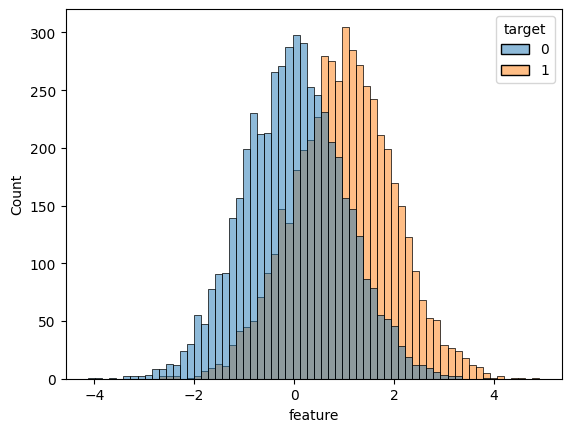

In [682]:
sns.histplot(df, x = 'feature', hue = 'target')

In [683]:
# запустите после того, как реализуете все функции 
woe_line(values=x, target=y, n_buckets=5)

### Эксперименты (2 балла)

#### №1 

Как будут меняться график, метрики разделяющей способности и $R^2$ при изменении дисперсии шума (параметр `noise_std`)? 

In [684]:
exp_arr = []
for noise_std in [0.3, 0.5, 1.5, 5, 10, 100]:
    np.random.seed(89)
    x = np.concatenate([sps.norm(0, noise_std).rvs(size = sample_size // 2), sps.norm(1, noise_std).rvs(size = sample_size // 2)])
    df['feature'] = x
    exp_arr.append((noise_std, woe_line(values=x, target=y, n_buckets=5)))

for exp in exp_arr:
    print(f"noise:\n{exp[0]}")
    exp[1].show()

noise:
0.3


noise:
0.5


noise:
1.5


noise:
5


noise:
10


noise:
100


Как мы видим, при $\sigma^2 \to \infty$ все метрики деградируют, но особенно плохо себя чувствуют roc-auc и IV, которые резко падают с ростом дисперсии, стремительно приближаясь к критичным значениям 1/2 и 0 соответстенно. $R^2$ же какое-то время продолжает показывать уверенную линейную связь, оставаясь высоким, но тоже в итоге затухает. Это связано с тем, что матожи наших распределений остаются неизменными, но их стандартное отклонение растёт, а в случае нормального распределение это значит, что распределения размазываются по прямой, перемешиваясь между собой, из-за чего разделять их становится сложнее. Кроме того, интересно заметить, что и радиус доверительных интервалов растёт, графически сначала это почти не видно, но с ростом дисперсии взрываются и доверительные интервалы.

#### №2 

Запустите функцию с `values=x ** 2`. Как по графику определить эту ситуацию? Что нужно делать в таком случае?

In [693]:
np.random.seed(89)
x = np.concatenate([sps.norm(0, 1).rvs(size = sample_size // 2), sps.norm(1, 1).rvs(size = sample_size // 2)])
woe_line(values=x ** 2, target=y, n_buckets=5)

По метрикам roc-auc упал с 0.76 до 0.637, но сильнее всего пострадала IV, упав с 0.882 до 0.245, $R^2$ остался более-менее высоким, но по нашим стандартам уже сигнализирует о том, что это нелинейно. Сама кривая выпукла вверх и напоминает корень, что вполне логично, так как WoE от нашей изначальной фичи примерно линеен, то есть $\text{WoE}_i(x) \approx kx + b$. Мы считаем, что накидываем сверху новую фичу $\xi_j = \xi_i^2 \Rightarrow \xi_i = \sqrt{\xi_j}$, то есть в этом случае $\text{WoE}_j(\hat x) \approx k \sqrt{\hat x} + b$, то есть график теперь должен выглядеть примерно как корень, что мы и наблюдаем. В этом случае мы всё равно потеряем какую-то информацию, потому что отрицательные значения уже перемешались с положительными, поэтому и их WoE перемешались, однако для сведения к линейности мы можем взять корень от нашей фичи и получить что-то примерно линейное, с чем-то посложнее для монотонности (например, корень с учетом знаков) можно не запариваться, так как тут видно, что отрицательных значений не осталось.

#### №3

Запустите функцию с `values=np.exp(x)`. Как по графику определить эту ситуацию? Что нужно делать в таком случае?

In [694]:
woe_line(values=np.exp(x), target=y, n_buckets=5)

roc-auc и IV никак не поменялись от таких трюков с фичей, но вот $R^2$ сильно просел, сигнализируя о нелинейности. Проводя аналогичные прошлому пункту рассуждения, можно понять, что WoE будет выгляеть примерно как логарифм, умноженный на константу и сдвинутый на другую константу, что мы и наблюдаем на графике. Соответственно, так как график очень напоминает нам логарифм, то мы должны взять логарифм от нашей фичи, чтобы получить что-то примерно линейное.

## Часть 2. Строим ЛогРег. (8 баллов)

В этом пунтке попробуем применить все наши навыки 

Скачайте датасет на EDU. Пароль вы найдете в телеграм-канале курса, в посте с анонсом домашки.

In [695]:
df = pd.read_csv('logreg_hw_5.csv', index_col=0)
df

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,d4p12
0,-1.444709,3.554779,1.308371,-0.000119,0.029628,3.829880,1,8.825418,3.829880,11.565953,-513.014565,-1.072893,7.936545,0.047069,B,1
1,1.132531,-0.207661,-2.142882,0.062686,0.859062,6.189545,1,3.453220,6.189545,4.935665,-39.351891,3.409855,17.015210,0.029288,A,0
2,1.268781,-0.243999,10000.000000,0.339225,0.614599,12.503629,1,-10.116061,12.503629,6.234414,-4.993050,3.121126,4.878602,0.237255,A,0
3,-1.278475,-2.579890,5.050763,-0.938956,0.090461,-1.080041,1,6.780814,-1.080041,2.682539,-509.273095,-1.242741,20.293025,0.907788,B,0
4,3.507807,0.152661,-8.905005,0.067646,0.216199,1.367184,1,-10.638134,1.367184,6.881602,-2.034797,2.814972,7.352399,0.276854,A,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,-3.061422,-0.163832,4.812768,-0.949937,0.224437,5.263508,1,-9.959913,5.263508,5.294558,-524.265291,-1.648415,5.410059,0.855190,B,0
99996,0.222451,-0.273191,0.380895,0.860607,0.950708,0.581767,1,-1.645952,0.581767,5.571499,-13.499956,3.386865,92.903615,0.006668,A,1
99997,1.078498,0.339526,-5.184847,0.242072,0.854085,0.995075,1,-5.565932,0.995075,-0.433263,3.928387,3.290285,1.233853,0.160933,A,1
99998,-1.431421,-0.605388,2.466023,-0.056519,0.736255,2.980562,1,-4.517188,2.980562,10.812813,-507.593408,-1.398568,1904.246147,0.077164,B,1


Как вы выдите, ```feature_1, ..., feature_14``` - числа 
```feature_15``` - категориальная фича

### Задание 0. EDA.

Как бы вы начали знакомиться с данными до построения модели? Постройте 3-5 графиков / таблиц, чтобы передать основную информацию о датасете.

In [696]:
df.columns, set(df['feature_15'])

(Index(['feature_1', 'feature_2', 'feature_3', 'feature_4', 'feature_5',
        'feature_6', 'feature_7', 'feature_8', 'feature_9', 'feature_10',
        'feature_11', 'feature_12', 'feature_13', 'feature_14', 'feature_15',
        'd4p12'],
       dtype='object'),
 {'A', 'B'})

Так как мы подходим к делу с вероятностной точки зрения, то в наших терминах у нас есть 16 возможно зависимых случайных величн, поэтому первым делом конечно хочется посмотреть на их распределения, чтобы понять, а с чем мы вообще имеем дело. Но для начала посмотрим на общую информацию о столбцах, которую нам любезно предоставляет pandas, для этого мы временно будем относиться к нашей категориальной фиче как к дискретной, чтобы посмотреть и на её распределение тоже (хотя в целом так делать не всегда стоит, так как мы задаём искусственный порядок в данных, что для линейных моделей чревато, поэтому потом вернём им изначальный вид).

In [697]:
df['feature_15'] = df['feature_15'].map({"A" : 0, "B" : 1})

In [698]:
df.describe()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,d4p12
count,100000.000000,100000.000000,100000.000000,1.000000e+05,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05,1.000000e+05,100000.000000,100000.000000
mean,-0.004065,-0.198827,-6.283870,-1.251609e-01,1.001067,2.990486,0.900280,-2.514795,2.990486,3.640370,-256.924907,1.013153,9.969348e+02,2.885691e-01,0.501060,0.425370
std,2.625003,169.576125,2344.152317,5.900464e-01,1.003677,3.997014,0.299628,5.009291,3.997014,4.977886,260.742462,2.314468,4.699415e+03,3.785086e-01,0.500001,0.494401
min,-54.598150,-38296.171946,-10000.000000,-1.999985e+00,0.000009,-18.732375,0.000000,-26.496544,-18.732375,-16.847030,-1012.820365,-9.210340,1.666947e-19,6.195140e-11,0.000000,0.000000
25%,-1.011666,-0.385200,-4.215224,-2.219215e-01,0.287134,0.288999,1.000000,-5.893561,0.288999,0.270052,-506.548930,-1.262413,3.451754e+00,1.371482e-03,0.000000,0.000000
50%,-0.058406,-0.072894,0.003200,-2.735552e-09,0.694543,3.001134,1.000000,-2.511154,3.001134,3.669848,-282.922772,-0.800022,2.341854e+01,4.439380e-02,1.000000,0.000000
75%,1.004057,0.395806,4.255211,1.096505e-01,1.383918,5.688353,1.000000,0.859395,5.688353,6.984301,-0.080408,3.344923,1.536384e+02,6.085319e-01,1.000000,1.000000
max,39.011329,20133.753873,10000.000000,9.999525e-01,11.629614,21.549778,1.000000,19.258719,21.549778,24.764462,446.685530,3.951220,3.729609e+05,1.000000e+00,1.000000,1.000000


Как мы видим отсюда, в наших данных нет пропусков, так как все столбцы имеют одинаковое количество, поэтому нам не придётся запариваться с тем, чтобы как-то заполнить недостающее данные.

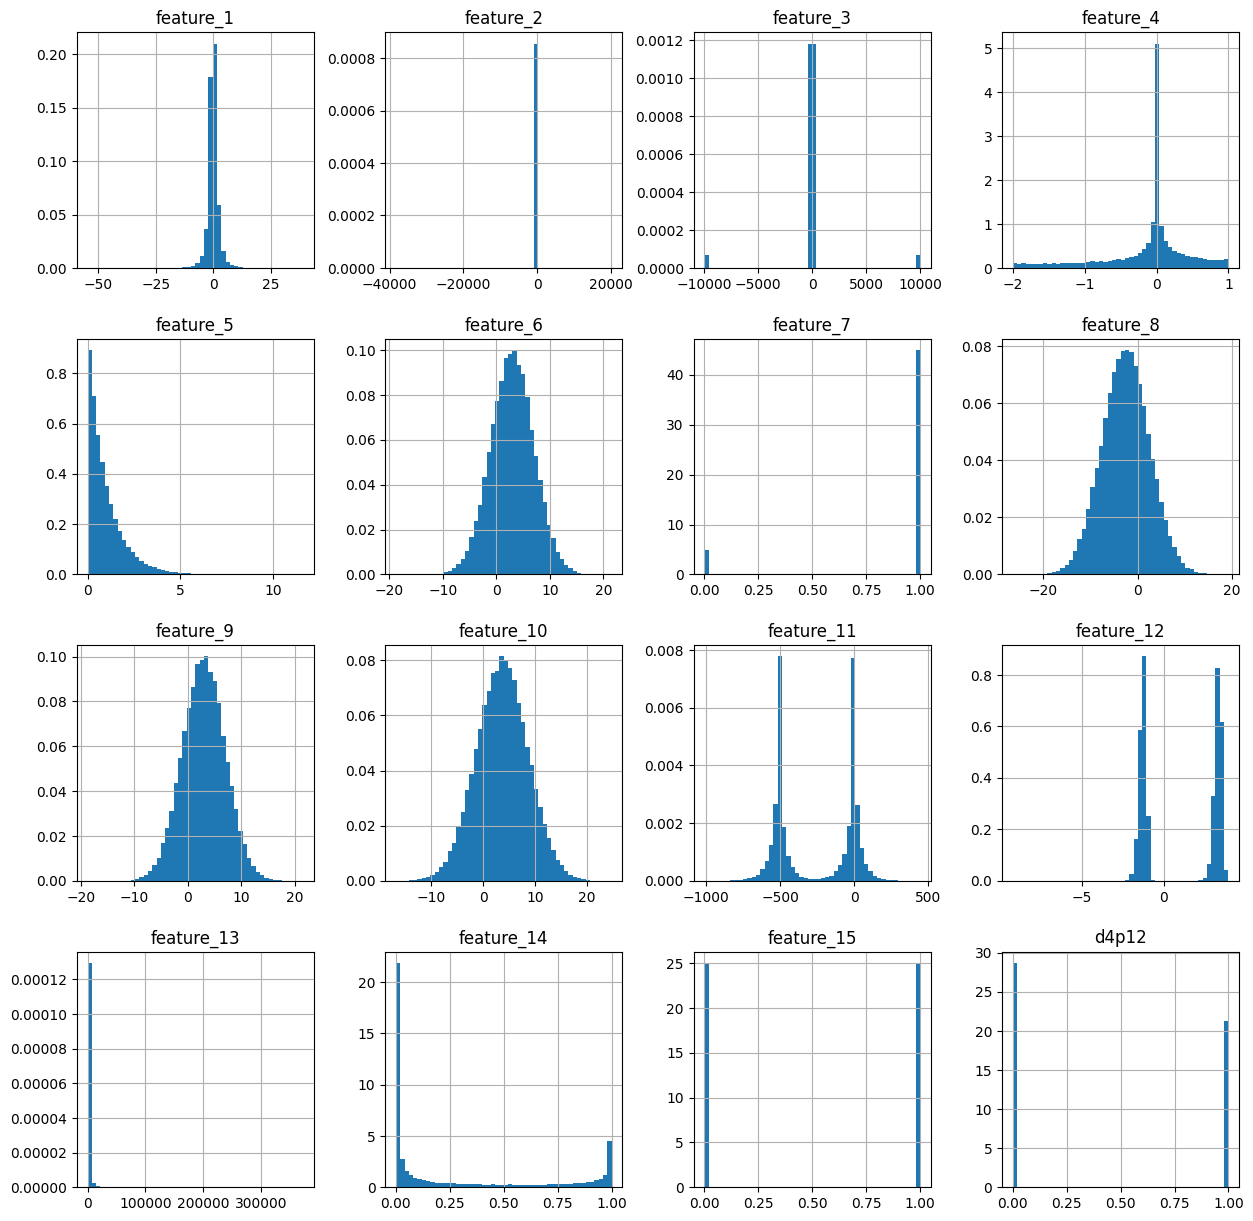

In [699]:
import matplotlib.pyplot as plt

df.hist(figsize=(15, 15), bins = 50, density = True)
plt.show()

По этим графикам видно, что у нас есть "хорошо" распределенные фичи(4, 6, 8, 9, 10), которые похожи визуально на какое-то околонормальное распределение; есть фичи, которые скорее всего нужно будет масштабировать (2, 13), потому что по их графикам видно, что большинство их значений сконцентрировано внутри маленького отрезка;  есть фичи, с какими-то выбросами (3), где есть значения с относительно небольшой вероятностью, но относительно далеко от общей массы находятся; есть фичи, с необычными, но приемлемыми распределениями(11, 12, 14), у которых есть несколько явных пиков; есть бинарная фича (7).

Затем было бы неплохо посмотреть, как друг с другом связаны фичи, считая между ними корреляции, но перед этим вернём 15-ой фичи её изначальную форму.

In [700]:
df['feature_15'] = df['feature_15'].map({0 : "A" , 1 :"B" })

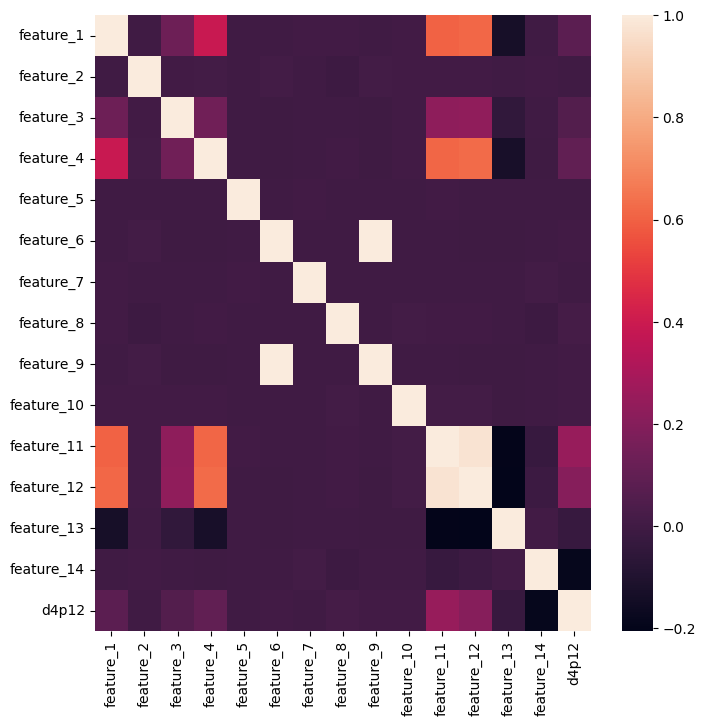

In [701]:
plt.figure(figsize=(8, 8))
sns.heatmap(df.corr(numeric_only=True))
plt.show()

Из этого графика можно сделать вывод о том, что 6 и 9 фичи - линейно связные, потому что у них единичный коэффициент корреляции; 11 и 12 фичи сильно связаны, так их коэффициент корреляции близок к 1, кроме того, они обе имеют довольно явную связь с 1 и 4 признаками, у которых между собой связь послабее; 3 имеет не очень сильную, но линейную связь с 1, 4, 11, 12; признак 13 с 1, 4, 11, 12 имеет коэффициент корреляции близкий к -0.2, что говорит о не очень сильной, но всё же обратной линейной связи. target же имеет не очень сильную обратную линейную связь с 14 фичей и не очень сильную линейную связь с 1, 3, 4, 11, 12.

### Задание 1. Бейзлайн.

Попробуйте построить ЛогРег только на числовых данных. Для этого разбейте датасет на трейн и тест (80/20). Перед обучением логрега стандартизуйте переменные. Это может быть полезно для численной устойчивости алгоритмов оптимизации.

Для этой модели и всех дальнейших:

1. Получилась ли модель линейной? Постройте график линейности на трейне и на тесте и сделайте вывод.
2. Расчитайте AUC и IV на трейне и на тесте. Что можно сказать о переобучении?

In [702]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [703]:
X = df.drop(columns=['feature_15', 'd4p12'])
y = df['d4p12']

X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, stratify=y)

In [704]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_test

array([[-2.53667279e-01, -1.38799731e-03,  7.51294684e-03, ...,
        -8.90515782e-01, -2.11794574e-01,  1.51164941e+00],
       [-5.60258267e-01, -5.18427884e-03,  5.05847555e-03, ...,
        -1.01262456e+00,  1.56285540e-01,  1.29135077e+00],
       [ 3.03736863e-01, -4.26953116e-03,  3.65141239e-03, ...,
         8.98340967e-01, -2.02074640e-01, -7.48943805e-01],
       ...,
       [-4.51990491e-01,  5.13394307e-03,  6.40125545e-03, ...,
        -9.96455942e-01, -2.13103136e-01,  2.31373517e-01],
       [-5.30705687e-01, -7.58772425e-04,  3.60899230e-03, ...,
        -9.06260465e-01, -1.55808228e-01, -6.80742364e-01],
       [-6.40935919e-01,  4.63887700e-03,  5.42242231e-03, ...,
        -9.49851183e-01,  2.85818236e-01, -7.42552835e-01]])

In [705]:
model = LogisticRegression()
model = model.fit(X_train, y_train)

У нас теперь 14 фичей $\xi = (\xi_1, \dots, \xi_{14})$, поэтому не очень понятно, как по ним всем проверять линейность модели. Однако мы помним, что модель будет линейный, если $\forall i \ WoE_i$ будет линейной функцией от $\xi_i$, в этом случае $\ln(\frac{P(y = 1 | \xi)}{P(y = 0 | \xi)}) = w^T\xi$. В ходе обучения мы подобрали оптимальные веста, то есть получили какое-то $w^T\xi =: \eta$, тогда ко всему этому можно относиться так, что у нас есть одна фича $\eta$, и мы проверяем линейность относительно неё. Очевидно, что если $WoE$ будет линеен относительно неё, то предпосылки будут выполнены и модель будет линейной. Благо, для этого у нас есть подходящие функции в sklearn.

In [706]:
eta_train = model.decision_function(X_train)
eta_test = model.decision_function(X_test)

woe_line(eta_train, y_train, 10).show()
woe_line(eta_test, y_test, 10).show()

Немного модель до линейности не дотягивает, хотя и довольно близко.

In [707]:
eta_train_buckets = calc_buckets(eta_train, 10)
eta_test_buckets = calc_buckets(eta_test, 10)
print(f"Train: {calc_plot_title(eta_train, y_train, eta_train_buckets)}\nTest: {calc_plot_title(eta_test, y_test, eta_test_buckets)}")

Train: AUC = 0.706 IV = 0.588 R_sqr = 0.976 
Test: AUC = 0.713 IV = 0.646 R_sqr = 0.973 


Забавно, но метрики выше на тесте, чем на трейне, обычно о переобучении свидетельствует обратная ситуация, так что переобучения тут нет.

### Задание 2. Добавляем категориальную переменную.

Повторите задание 1, включив в модель категориальную переменную (например, с помощью one-hot encoding).

Улучшилось ли качество?

In [750]:
from sklearn.preprocessing import OneHotEncoder

X = df.drop(columns=['d4p12'])
y = df['d4p12']

# Вроде как я не смог придумать, как модель
# сможет получить хоть какие-то данные о
# тесте в трейне, если мы сделаем энкодинг
# до сплита, поэтому пусть будет так.

encoder = OneHotEncoder(sparse_output=False, drop='first')
cat_f = encoder.fit_transform(X[['feature_15']])
X = pd.concat([X, pd.DataFrame(cat_f, index = X.index, columns = ['feature_15_enc'])], axis=1)
X = X.drop(columns = ['feature_15'])
X.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15_enc
0,-1.444709,3.554779,1.308371,-0.000119,0.029628,3.829880,1,8.825418,3.829880,11.565953,-513.014565,-1.072893,7.936545,0.047069,1.0
1,1.132531,-0.207661,-2.142882,0.062686,0.859062,6.189545,1,3.453220,6.189545,4.935665,-39.351891,3.409855,17.015210,0.029288,0.0
2,1.268781,-0.243999,10000.000000,0.339225,0.614599,12.503629,1,-10.116061,12.503629,6.234414,-4.993050,3.121126,4.878602,0.237255,0.0
3,-1.278475,-2.579890,5.050763,-0.938956,0.090461,-1.080041,1,6.780814,-1.080041,2.682539,-509.273095,-1.242741,20.293025,0.907788,1.0
4,3.507807,0.152661,-8.905005,0.067646,0.216199,1.367184,1,-10.638134,1.367184,6.881602,-2.034797,2.814972,7.352399,0.276854,0.0


In [751]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.8, stratify=y)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression()
model = model.fit(X_train, y_train)

In [752]:
eta_train = model.decision_function(X_train)
eta_test = model.decision_function(X_test)

woe_line(eta_train, y_train, 10).show()
woe_line(eta_test, y_test, 10).show()

С точки зрения линейности стало всё куда лучше, теперь мы прибизились к линейности даже по метрике $R^2$, которая составляет $\approx 0.98$, визуально почти все точки лежат на примерно одной прямой, кроме первой и последней точек.

In [753]:
eta_train_buckets = calc_buckets(eta_train, 10)
eta_test_buckets = calc_buckets(eta_test, 10)
print(f"Train: {calc_plot_title(eta_train, y_train, eta_train_buckets)}\nTest: {calc_plot_title(eta_test, y_test, eta_test_buckets)}")

Train: AUC = 0.860 IV = 2.257 R_sqr = 0.980 
Test: AUC = 0.860 IV = 2.286 R_sqr = 0.988 


Как мы видим, качество относительного прошлого эксперимента серьёзно повысилось, теперь roc-auc на вполне высокое значение 0.86 (причём на тесте результаты снова чуть повыше, что снова свидетельствует об отсутствии переобучения), что примерно на 0.13 выше прошлого прогона.

### Задание 3. Линеаризация переменных.

На самом деле, категориальные переменные можно учитывать в моделях совсем по-другому. С их помощью можно выделить в модели сегменты. Каждому сегменту соответствует своя модель (в нашем случае логрег). 

Примером такой сегментации может стать сегментация по наличию кредитной истории. В этом случае на разных сегментах будут не просто отдельные модели, но и даже разный изначальный набор признаков. Другое свидетельство удачной сегментации – разный характер зависимости признаков и целевой переменной. Это можно увидеть на графике линейности признака по WoE. Этим мы и займемся далее.

Используйте переменную 15 для сегментации модели. На каждом из двух сегментов линеаризуйте переменные. Для этого приложите:
 - график линейности переменной до преобразования
 - график после подобранного преобразования

Помимо этого:
 - попробуйте линеаризовать какие-нибудь 2 переменные *на всей выборке*. Получилось ли у вас что-то? Постройте график.
 - по графику линейности определите шумовые (либо слабоинформативные) переменные. В конце задания приложите их список.

In [875]:
seg_1 = df[df['feature_15'] == 'A'].drop(columns = ['feature_15']).reset_index(drop = True)
seg_2 = df[df['feature_15'] == 'B'].drop(columns = ['feature_15']).reset_index(drop = True)
seg_2.head()

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,d4p12
0,-1.444709,3.554779,1.308371,-0.000119,0.029628,3.829880,1,8.825418,3.829880,11.565953,-513.014565,-1.072893,7.936545,0.047069,1
1,-1.278475,-2.579890,5.050763,-0.938956,0.090461,-1.080041,1,6.780814,-1.080041,2.682539,-509.273095,-1.242741,20.293025,0.907788,0
2,-0.773616,-0.320438,-1.658311,-0.012746,1.226802,4.070613,1,0.358136,4.070613,4.048045,-494.737926,-1.381005,1182.376053,0.936676,0
3,-0.748825,0.260512,-3.468750,-0.407669,2.167238,3.671383,1,3.073309,3.671383,8.258053,-494.944584,-1.205677,103.739456,0.126881,1
4,-1.467083,-0.274845,0.435544,-0.277728,3.451413,11.812456,1,-1.591799,11.812456,9.104183,-589.471300,-1.361750,55.949296,0.959790,0


In [755]:
import re

seg_1_r2_arr = []
seg_2_r2_arr = []
seg_1_iv_arr = []
seg_2_iv_arr = []

for i, c in enumerate(list(seg_1.drop(columns = ['d4p12']).columns)):
    values = np.asarray(seg_1[c])
    target =  np.asarray(seg_1['d4p12'].values)

    bucks = calc_buckets(values, 10)
    match = re.search(r"AUC = ([\d\.]+) IV = ([\d\.]+) R_sqr = ([\d\.]+)", calc_plot_title(values, target, bucks))

    seg_1_r2_arr.append(float(match.group(3)))
    seg_1_iv_arr.append(float(match.group(2)))

    values = np.asarray(seg_2[c])
    target = np.asarray(seg_2['d4p12'].values)
    
    bucks = calc_buckets(values, 10)
    match = re.search(r"AUC = ([\d\.]+) IV = ([\d\.]+) R_sqr = ([\d\.]+)", calc_plot_title(values, target, bucks))

    seg_2_r2_arr.append(float(match.group(3)))
    seg_2_iv_arr.append(float(match.group(2)))

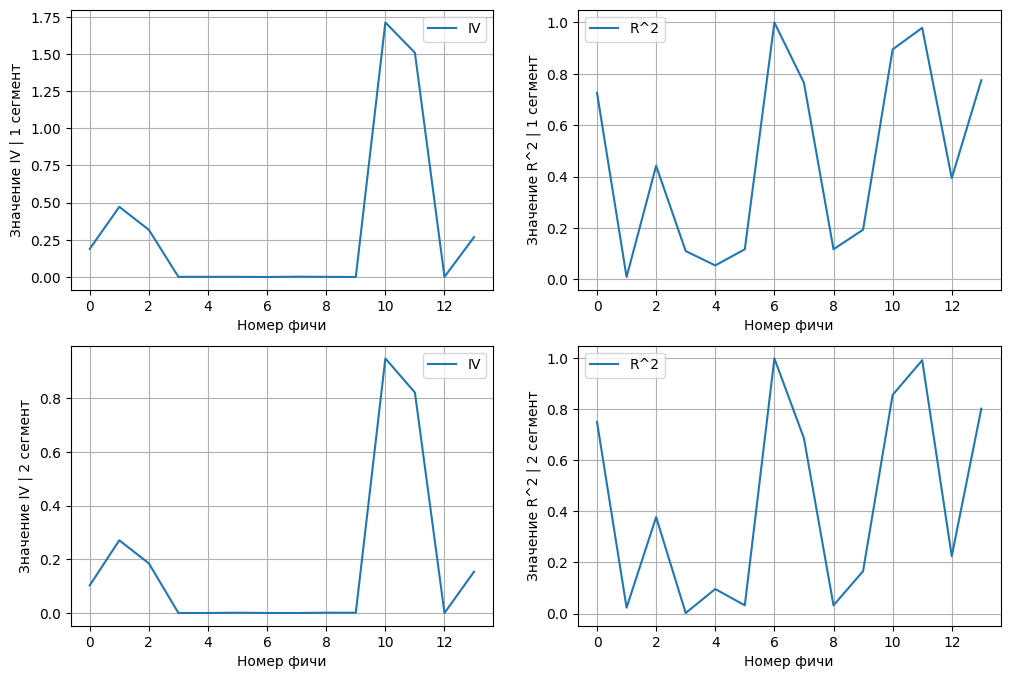

In [756]:
fig, axes = plt.subplots(2, 2, figsize = (12, 8))
x_line = np.arange(0, len(seg_1_iv_arr))

axes[0][0].plot(x_line, seg_1_iv_arr, label = 'IV')
axes[0][0].set_xlabel("Номер фичи") 
axes[0][0].set_ylabel("Значение IV | 1 сегмент")
axes[0][0].legend()
axes[0][0].grid()

axes[0][1].plot(x_line, seg_1_r2_arr, label = 'R^2')
axes[0][1].set_xlabel("Номер фичи")
axes[0][1].set_ylabel("Значение R^2 | 1 сегмент")
axes[0][1].legend()
axes[0][1].grid()

axes[1][0].plot(x_line, seg_2_iv_arr, label = 'IV')
axes[1][0].set_xlabel("Номер фичи")
axes[1][0].set_ylabel("Значение IV | 2 сегмент")
axes[1][0].legend()
axes[1][0].grid()

axes[1][1].plot(x_line, seg_2_r2_arr, label = 'R^2')
axes[1][1].set_xlabel("Номер фичи")
axes[1][1].set_ylabel("Значение R^2 | 2 сегмент")
axes[1][1].legend()
axes[1][1].grid()

plt.show()

Раз нам нужно найти малоинформативные фичи, то и отбирать мы будем визуально как раз по IV, поэтому список кандидатов на малоинформативность по сегментам одинаков:

**4, 5, 6, 7, 8, 9, 10, 13**


**Сейчас будем пытаться линеаризовать какие-нибудь две переменные по всей выборке.**

In [757]:
woe_line(np.asarray(df['feature_3']), np.asarray(df['d4p12']), 10).show()

К сожалению, эту переменную не получается напрмяую линеаризировать с использованием адекватного количество преобразований адекватного вида, потому что околонулевые значения дают сильный разброс по WoE и принимает сильно разные значения, поэтому тут разумнее закидывать флажок нуля в логрег и пусть он сам разбирается.

In [758]:
woe_line(np.asarray(df['feature_1']), np.asarray(df['d4p12']), 10).show()

Вот это уже куда приятнее прошлого графика, похоже на какой-то перевернутый $\ln(|x|)$, его и попробуем.

In [759]:
woe_line(np.log(np.abs(np.asarray(df['feature_1']))), np.asarray(df['d4p12']), 10).show()

Таким образом, на всей выборке есть как фичи, у которых линеаризация скорее всего приведёт к переобучение, потому что будет очень перегруженный, так и фичи, которые вполне адекватно линеаризуются.

**Начинаем перебор! Будем пытаться линеаризовывать все фичи сегментов, бугага!**

In [876]:
target_s_1 = np.asarray(seg_1['d4p12'])
target_s_2 = np.asarray(seg_2['d4p12'])

1)

In [877]:
woe_line(np.asarray(seg_1['feature_1']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_1']), target_s_2, 10).show()

Как-то эти графики напоминают график экспоненты, только с разными знаками, нижний график особенно, поэтому проверим её.

In [878]:
woe_line(np.exp(- np.asarray(seg_1['feature_1'])), target_s_1, 10).show()
woe_line(np.exp(np.asarray(seg_2['feature_1'])), target_s_2, 10).show()

In [879]:
seg_1.loc[:, 'feature_1'] = np.exp(-seg_1['feature_1'])
seg_2.loc[:, 'feature_1'] = np.exp(seg_2['feature_1'])

2)

In [880]:
woe_line(np.asarray(seg_1['feature_2']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_2']), target_s_2, 10).show()

Похоже подозрительно на какую-то функцию типа $\frac{1}{x}$, так как в нуле подрываемся, но потом сплющиваемся, но на всякий случай в знаменатель закинем какой-нить маленький эпсилон, чтобы не взорваться на реальном нуле.

In [881]:
woe_line(1 / (np.asarray(seg_1['feature_2']) + 0.0001), target_s_1, 10).show()
woe_line(1 / (np.asarray(seg_2['feature_2']) + 0.0001), target_s_2, 10).show()

In [882]:
seg_1.loc[:, 'feature_2'] = 1 / (seg_1['feature_2'] + 0.0001)
seg_2.loc[:, 'feature_2'] = 1 / (seg_2['feature_2'] + 0.0001)

3)

In [883]:
woe_line(np.asarray(seg_1['feature_3']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_3']), target_s_2, 10).show()

Ну тут только клип поможет..

In [893]:
woe_line(np.clip(np.asarray(seg_1['feature_3']), a_min = 1.5, a_max=3.5), target_s_1, 10).show()
woe_line(np.clip(np.asarray(seg_2['feature_3']), a_min = 0.1, a_max=10), target_s_2, 10).show()

In [894]:
seg_1.loc[:, 'feature_3'] = seg_1['feature_3'].clip(lower=1.5, upper=3.5)
seg_2.loc[:, 'feature_3'] = seg_2['feature_3'].clip(lower=0.1, upper=10)


4)

In [895]:
woe_line(np.asarray(seg_1['feature_4']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_4']), target_s_2, 10).show()

Тут начинается серия интересных экземпляров, начинающаяся с этой шумной(судя по огромным доверительным интервалам и хаотичным точкам) и не очень информативной 4-ой фичи. Несмотря на то, что таргет коррелирует с ней, линеаризировать её, не переобучившись, кажется очень сложным, потому что здесь точно придётся использовать несколько неочевидных преобразований.

5) 

In [896]:
woe_line(np.asarray(seg_1['feature_5']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_5']), target_s_2, 10).show()

Аналогично четвёртой, только тут ещё и корреляции явной с таргетом нет.

6) 

In [897]:
woe_line(np.asarray(seg_1['feature_6']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_6']), target_s_2, 10).show()

Аналогично пятой.

7) Седьмая фича дискретная, так ещё и бинарная. Кажется, что линеаризовать её нет никакого смысла.

In [898]:
woe_line(np.asarray(seg_1['feature_7']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_7']), target_s_2, 10).show()

8)

In [899]:
woe_line(np.asarray(seg_1['feature_8']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_8']), target_s_2, 10).show()

Аналогично пятой и шестой, мусорная фича без корреляции.

9)

In [900]:
woe_line(np.asarray(seg_1['feature_9']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_9']), target_s_2, 10).show()

Как и несколько прошлых, roc-auc, iv и корреляции втроём заверяют, что она бесполезна.

10)

In [901]:
woe_line(np.asarray(seg_1['feature_10']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_10']), target_s_2, 10).show()

Абсолютно аналогично прошлой фиче.

11)

In [902]:
woe_line(np.asarray(seg_1['feature_11']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_11']), target_s_2, 10).show()

А вот это уже лучше, да ещё и похоже на $x^{\frac{1}{3}}$, попробуем её, однако немного поработаем с знаками, так как питон на возведение отрицательного числа в такую степень ругается, а для второй не подходит ни возведение в такую степень с предварительным сдвигом, ни сдвиг и арктангенс, ни сдвиг и тангенс, поэтому попробуем её просто клипнуть.

In [903]:
woe_line(np.sign(np.asarray(seg_1['feature_11'])) * np.abs(np.asarray(seg_1['feature_11'])) ** (1/3), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_11']).clip(min = -550, max = -465), target_s_2, 10).show()

In [904]:
seg_1.loc[:, 'feature_11'] = np.sign(np.asarray(seg_1['feature_11'])) * np.abs(np.asarray(seg_1['feature_11'])) ** (1/3)
seg_2.loc[:, 'feature_11'] = seg_2['feature_11'].clip(lower=-550, upper=-465)

12)

In [905]:
woe_line(np.asarray(seg_1['feature_12']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_12']), target_s_2, 10).show()

Джекпот.

13)

In [906]:
woe_line(np.asarray(seg_1['feature_13']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_13']), target_s_2, 10).show()

К сожалению, несмотря на странные обратные корреляции, по roc-auc и IV это мусорная фича.

14)

In [907]:
woe_line(np.asarray(seg_1['feature_14']), target_s_1, 10).show()
woe_line(np.asarray(seg_2['feature_14']), target_s_2, 10).show()

Так как тут всё неотрицательно, то логарифм сам напрашивается, поэтому и попробуем его, только ещё применим клип до кучи, чтобы добить до линейности.

In [908]:
woe_line(np.log(np.asarray(seg_1['feature_14'])).clip(min = -10, max = -0.15), target_s_1, 10).show()
woe_line(np.log(np.asarray(seg_2['feature_14'])).clip(min = -10, max = -1), target_s_2, 10).show()

In [909]:
seg_1.loc[:, 'feature_14'] = np.log(np.asarray(seg_1['feature_14'])).clip(min=-10, max=-0.15)
seg_2.loc[:, 'feature_14'] = np.log(np.asarray(seg_2['feature_14'])).clip(min=-10, max=-1)

**Финальный список мусорных фич**:

4, 5, 6, 8, 9, 10, 13

### Задание 4. Финальная модель.

Обучите модели на признаках, которые вы отобрали и линеаризовали в задании 3. Пусть $logit_A$ – модель, обученная на сегменте $feature_{15} = A$. $logit_B$ – модель на втором сегменте. Тогда модель на всей выборке будем считать по формуле

$$
logit(x) = \mathbb I \{ feature_{15} = A \} \times logit_A(x) + \mathbb I \{ feature_{15} = B \} \times logit_B(x)
$$


Посчитайте для этой модели AUC и IV, оцените линейность на трейне и тесте. Сравните результаты с бейзлайном из задания 1.

Подсказка: если вы все сделали правильно, можно ожидать ROC AUC около 0.9 на тестовой выборке.

Так как мусорные фичи представлены чуть выше, то возьмём только те фичи, что линеаризованы и несут информационный смысл.

In [910]:
seg_1_finale = seg_1.drop(columns=['feature_4', 'feature_5', 'feature_6', 'feature_8', 'feature_9', 'feature_10', 'feature_13'])
seg_1_finale

,feature_1,feature_2,feature_3,feature_7,feature_11,feature_12,feature_14,d4p12
0,0.322217,-4.817849,1.5,1,-3.401380,3.409855,-3.530580,0
1,0.281174,-4.100054,3.5,1,-1.709183,3.121126,-1.438620,0
2,0.029963,6.546182,1.5,1,-1.267186,2.814972,-1.284263,0
3,0.210680,-2.855410,1.5,1,-3.339659,3.372350,-0.150000,0
4,0.181984,0.146622,1.5,1,-1.343465,3.150060,-0.150000,0
...,...,...,...,...,...,...,...,...
49889,0.455074,-1.154976,1.5,1,3.535577,3.102307,-0.150000,0
49890,0.486458,-3.543300,1.5,1,0.676527,3.325720,-4.985105,1
49891,0.800554,-3.661781,1.5,1,-2.381099,3.386865,-5.010381,1
49892,0.340106,2.944418,1.5,1,1.577871,3.290285,-1.826770,1


In [ ]:
s1_target = seg_1_finale['d4p12']
s1_data = seg_1_finale.drop(columns=['d4p12'])
s1_X_train, s1_X_test, s1_y_train, s1_y_test = train_test_split(s1_data, s1_target, train_size=0.8, stratify=s1_target)
s1_X_test.head()

,feature_1,feature_2,feature_3,feature_7,feature_11,feature_12,feature_14
3379,0.519578,3.644818,1.5,1,2.812057,3.313892,-10.000000
2310,0.439432,-0.888624,1.5,1,2.043934,3.184352,-0.817385
45586,0.011221,9.264391,1.5,1,-4.426020,3.177369,-0.150000
2167,0.046474,-2.893584,1.5,1,-5.911835,3.238587,-4.721433
48139,0.563313,0.596396,1.5,1,-0.878495,3.473700,-7.630270


In [915]:
scaler = StandardScaler()
s1_X_train = scaler.fit_transform(s1_X_train)
s1_X_test = scaler.transform(s1_X_test)
s1_X_test

array([[ 0.52717635,  0.78193116, -0.41501612, ...,  0.97235328,
        -0.03191776, -1.79783452],
       [ 0.22313388, -0.04739084, -0.41501612, ...,  0.71900073,
        -0.61621696,  0.89800621],
       [-1.40133943,  1.80994362, -0.41501612, ..., -1.41500341,
        -0.6477107 ,  1.09393779],
       ...,
       [-0.80870445,  1.19210051, -0.41501612, ..., -0.19212494,
        -0.08109195,  1.07709985],
       [-1.26623868, -1.73949535, -0.41501612, ..., -0.7018173 ,
         0.73707807,  1.09393779],
       [ 0.8606092 ,  1.19732091,  2.73696305, ..., -0.26505838,
        -0.68582164,  0.28343419]])

In [925]:
s1_model = LogisticRegression()
s1_model = s1_model.fit(s1_X_train, s1_y_train)

roc_auc_score(s1_y_test, s1_model.predict_proba(s1_X_test)[:, 1])

np.float64(0.9383968454948036)

In [926]:
seg_2_finale = seg_2.drop(columns=['feature_4', 'feature_5', 'feature_6', 'feature_8', 'feature_9', 'feature_10', 'feature_13'])

s2_target = seg_2_finale['d4p12']
s2_data = seg_2_finale.drop(columns=['d4p12'])

s2_X_train, s2_X_test, s2_y_train, s2_y_test = train_test_split(s2_data, s2_target, train_size=0.8, stratify=s2_target)

scaler_s2 = StandardScaler()
s2_X_train = scaler_s2.fit_transform(s2_X_train)
s2_X_test = scaler_s2.transform(s2_X_test)

s2_model = LogisticRegression()
s2_model = s2_model.fit(s2_X_train, s2_y_train)

roc_auc_score(s2_y_test, s2_model.predict_proba(s2_X_test)[:, 1])

np.float64(0.8340414457972674)

In [927]:
s1_eta_train = s1_model.decision_function(s1_X_train)
s1_eta_test = s1_model.decision_function(s1_X_test)

woe_line(s1_eta_train, s1_y_train, 10).show()
woe_line(s1_eta_test, s1_y_test, 10).show()

In [928]:
s2_eta_train = s2_model.decision_function(s2_X_train)
s2_eta_test = s2_model.decision_function(s2_X_test)

woe_line(s2_eta_train, s2_y_train, 10).show()
woe_line(s2_eta_test, s2_y_test, 10).show()

# Часть 3. Бонус. (3 балла)

На лекции мы накопили ряд упражнений, которые стоит решить для понимания происходившего. Вы можете $\TeX$ать их прямо в ноуте (или прикреплять картинки, если так удобнее).

#### **Упражнение 1**

Для определения $WoE$ мы пользовались Теоремой Байеса. Примените ее и **покажите, что верно равенство**:

$$
\ln \left(  \frac{P(x_i|y=1)}{P(x_i|y=0)} \right) = ... = \ln \left( \frac{P(y=1|x_i)}{P(y=0|x_i)} \right) - \ln \left( \frac{P(y=1)}{P(y=0)} \right)
$$

Распишем всё подробно:
$$
P(x_i | y = 1) = \frac{P(x_i \cap y = 1)}{ P(y = 1)} = \frac{P(y = 1 | x_i) P(x_i)}{P(y = 1)}
$$
Аналогично:
$$
P(x_i | y = 0) =  \frac{P(x_i \cap y = 0)}{ P(y = 0)} = \frac{P(y = 0 | x_i) P(x_i)}{P(y = 0)}
$$
Мёрджим:
$$
\ln{\frac{P(x_i | y = 1)}{P(x_i | y = 0)}} = \ln(P(x_i | y = 1)) - \ln(P(x_i | y = 0)) = \ln(\frac{P(y = 1 | x_i) P(x_i)}{P(y = 1)}) - \ln(\frac{P(y = 0 | x_i) P(x_i)}{P(y = 0)}) =
$$
$$
= \ln(P(y = 1 | x_i)) + \ln(P(x_i)) - \ln(P(y = 1)) - \ln(P(y = 0 | x_i)) - \ln(P(x_i)) + \ln(P(y = 0)) = \ln(\frac{P(y = 1 | x_i)}{P(y = 0 | x_i)}) - \ln(\frac{P(y = 1)}{P(y = 0)})
$$
Ну и получили нужную формулу.

#### **Упражнение 2**

Известно:

$WoE$ можно посчитать так:
$WoE_i(x_i) = \ln \Big ( \frac{B_i}{G_i} \Big ) - \ln \Big ( \frac{B}{G} \Big ) $

Частота выхода в дефолт:  $badrate = \frac{B}{B+G}; \quad badrate_i = \frac{B_i}{B_i+G_i}$

$
\sigma (x) = \frac{1}{1+e^{-x}}; \quad logit(x) = \ln \left( \frac{x}{1-x} \right)
$

**Покажите, что**
$WoE_i(x_i) = logit(badrate_i) - logit(badrate)$

Распишем формулу для логита:
$$
\text{logit}(badrate) = \text{logit}(\frac{B}{B + G}) = \ln (\frac{\frac{B}{B + G}}{1 - \frac{B}{B + G}}) = \ln (\frac{B}{B + G}) - \ln(\frac{B + G}{B + G} - \frac{B}{B + G}) = \ln(\frac{B}{B + G}) - \ln(\frac{G}{B + G}) = \ln (\frac{B}{G})
$$
Аналогично:
$$
\text{logit}(batrate_i) = \dots = \ln (\frac{B_i}{G_i})
$$
Тогда соберём всё воедино:
$$
\text{logit}(batrate_i) - \text{logit}(batrate) = \ln (\frac{B_i}{G_i}) - \ln (\frac{B}{G}) = \text{WoE}_i(x) \Rightarrow показали.
$$

#### **Упражнение 3**

Пусть даны два дискретных распределения: 

$B=(b_1, ..., b_n)$ и $G=(g_1, ..., g_n)$.

KL-дивергенция для дискретных распределений

$$D_{KL}(B||G) = \sum_{j=1}^{n} b_j \ln \left( \frac{b_j}{g_j} \right)$$


Пусть $x$ - дикретный признак, принмиающий значения $x_1,...,x_n$.
Известно определение IV через KL-дивергенцию:

$$
IV_x = D_{KL}(B_x||G_x)+D_{KL}(G_x||B_x)
$$
где 

$$
B_x (x_i) = P(x=x_i|y=1) = b_i; \quad G_x (x_i) = P(x=x_i|y=0) = g_i
$$

**Выразите $IV$ через $WoE$**





Распишем дивергенцию:
$$
D_{KL}(B_x || G_x) = \sum_{i=1}^n b_i \ln(\frac{b_i}{g_i}) = \sum_{i=1}^n b_i \ln(\frac{1}{g_i}) - \sum_{i=1}^n b_i \ln(\frac{1}{b_i}) = \sum_{i=1}^n P(x = x_i | y = 1) \ln(\frac{1}{P(x = x_i | y = 0)}) - \sum_{i=1}^n P(x = x_i | y = 1) \ln(\frac{1}{P(x = x_i | y = 1)}) =
$$
$$
=  \sum_{i=1}^n P(x = x_i | y = 1) \ln(\frac{P(x = x_i | y = 1)}{P(x = x_i | y = 0)}) = \sum_{i=1}^n P(x = x_i | y = 1) \text{WoE}_x(x_i)
$$
Аналогично:
$$
D_{KL}(G_x || B_x) = \sum_{i=1}^n g_i \ln(\frac{1}{b_i}) - \sum_{i=1}^n g_i \ln(\frac{1}{g_i}) = \sum_{i=1}^n P(x = x_i | y = 0) \ln(\frac{1}{P(x = x_i | y = 1)}) - \sum_{i=1}^n P(x = x_i | y = 0) \ln(\frac{1}{P(x = x_i | y = 0)}) = 
$$
$$
= \sum_{i=1}^n P(x = x_i | y = 0) \ln (\frac{P(x = x_i | y = 0)}{P(x = x_i | y = 1)}) = - \sum_{i=1}^n P(x = x_i | y = 0) \text{WoE}_x(x_i)
$$
А тогда:
$$
IV_x = D_{KL}(B_x || G_x) + D_{KL}(G_x || B_x) = \sum_{i=1}^n (P(x = x_i | y = 1) - P(x = x_i | y = 0)) \text{WoE}_x(x_i)
$$